# 02 𓏻 Cont–Kokholm: one model for S&P and VIX options

Index and VIX options have opposite smiles. S&P 500 smiles slope **down**, because puts are
expensive. VIX smiles slope **up**, because calls on volatility are expensive. Heston gets
the index right and the VIX backwards (notebook 04, section 6).

Cont & Kokholm (2013) model forward variance swap rates directly and add upward jumps in
variance, mirrored by downward jumps in the index. The claim to test is that one parameter
set then produces both smiles. We reproduce the paper's figures with its Table 2
parameters, for Gaussian (Merton) and double-exponential (Kou) jumps, and check that each
smile has the right shape.

Maths: [docs/cont_kokholm.md](../docs/cont_kokholm.md). Notebook 03 tests the
implementation itself.

In [1]:
import warnings

import _style as st
import matplotlib.pyplot as plt
import numpy as np

from finpricing import VixModel
from finpricing.data.fixtures import (
    KOU_B_I,
    KOU_PARAMS,
    MERTON_B_I,
    MERTON_PARAMS,
    TENOR_DATES,
    VI_0,
)
from finpricing.utils.bs_utils import implied_volatility

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.random.seed(2013)                       # the jump simulation uses NumPy's global generator

NUM_PATHS = 200_000                        # the paper uses 2,000,000; raise for smoother index smiles
R = 0.0                                    # the paper works with zero rates
LABELS = [f"{round(T * 12)}m" for T in TENOR_DATES[1:]]
COLORS = {"Merton": st.OXIDE, "Kou": st.INDIGO}

models = {"Merton": VixModel(model_type="Merton"), "Kou": VixModel(model_type="Kou")}
for model in models.values():
    model.store_tenor_data(NUM_PATHS)

## 1 𓏺 Parameters (Table 2)

The paper's Table 2, used for every figure below.

In [2]:
rows = [("ω  vol of variance", "omega"), ("k₁ diffusion decay", "k1"), ("k₂ jump decay", "k2"),
        ("λ  jump intensity", "lmbd"), ("ρ  correlation", "rho")]
print(f"{'':24}{'Merton':>9}{'Kou':>9}")
for label, name in rows:
    print(f"{label:24}{getattr(MERTON_PARAMS, name):>9.2f}{getattr(KOU_PARAMS, name):>9.2f}")
print(f"{'m, δ  jump mean, std':24}{MERTON_PARAMS.m:>9.2f}{MERTON_PARAMS.delta:>9.2f}  (Merton only)")
print(f"{'p, α₊, α₋  Kou jumps':24}{KOU_PARAMS.p:>9.2f}{KOU_PARAMS.alpha_plus:>9.2f}{KOU_PARAMS.alpha_minus:>9.2f}  (Kou only)")
print()
print("tenors        ", "  ".join(f"{label:>6}" for label in LABELS))
print("V^i_0         ", "  ".join(f"{v:>6.3f}" for v in VI_0))
print("b_i Merton    ", "  ".join(f"{v:>6.3f}" for v in MERTON_B_I))
print("b_i Kou       ", "  ".join(f"{v:>6.3f}" for v in KOU_B_I))

                           Merton      Kou
ω  vol of variance           2.04     1.98
k₁ diffusion decay          21.90    22.30
k₂ jump decay                2.07     2.20
λ  jump intensity            3.52    13.60
ρ  correlation              -0.45    -0.45
m, δ  jump mean, std         0.54     0.25  (Merton only)
p, α₊, α₋  Kou jumps         0.86     4.25    19.90  (Kou only)

tenors             1m      2m      3m      4m      7m     10m
V^i_0           0.041   0.052   0.056   0.059   0.062   0.061
b_i Merton     -0.140  -0.161  -0.162  -0.187  -0.198  -0.199
b_i Kou        -0.141  -0.159  -0.158  -0.187  -0.195  -0.192


## 2 𓏻 VIX option smiles

We start with the side Heston gets wrong. VIX options are priced by Fourier inversion of the
VIX characteristic function. With the VIX future normalised to 1, the Black implied
volatility rises with the strike at every maturity: out-of-the-money calls on volatility are
expensive, as in the market.

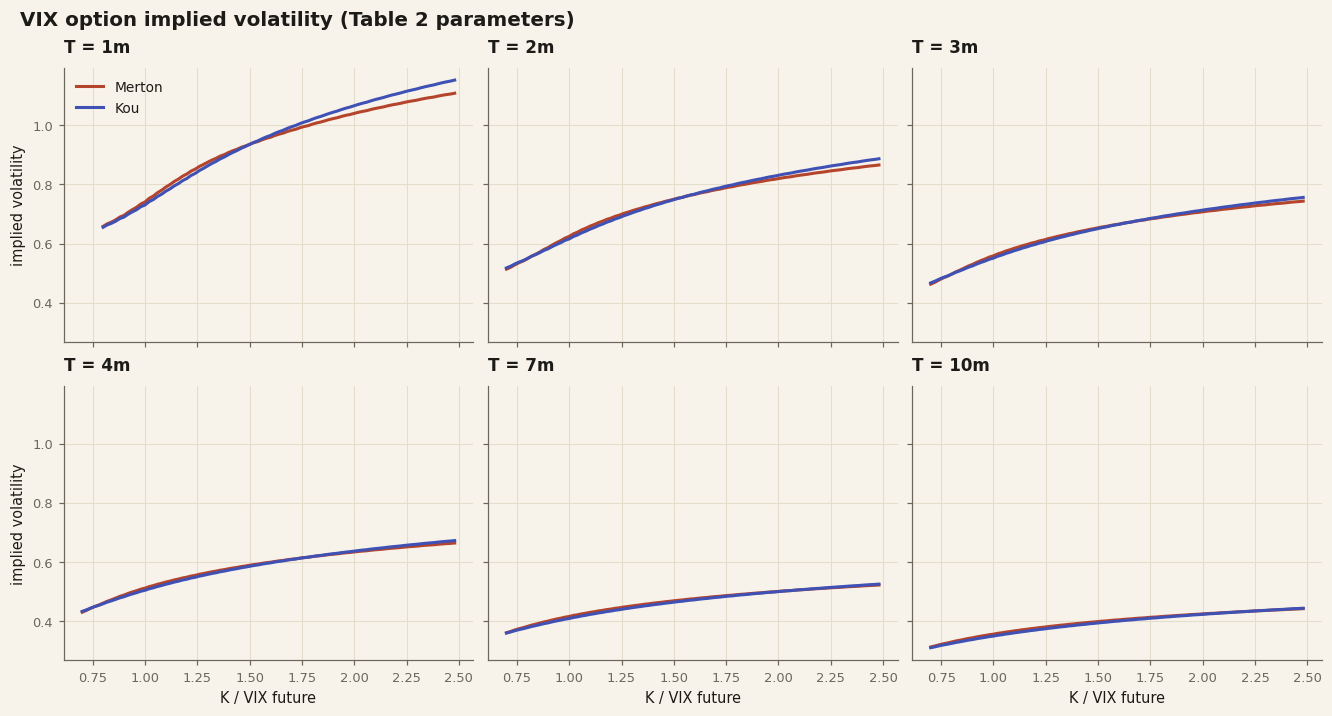

𓋹 PASS  Merton: VIX smile rises from the money to 1.5× at every maturity
𓋹 PASS  Kou: VIX smile rises from the money to 1.5× at every maturity


In [3]:
vix_smiles = {}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4), sharex=True, sharey=True)
for j, (ax, T) in enumerate(zip(axes.flat, TENOR_DATES[1:], strict=True)):
    ks = np.arange(0.8 if j == 0 else 0.7, 2.5, 0.02)
    for name, model in models.items():
        prices = np.array([model.vix_option_pricer(1.0, k, T, R) for k in ks])
        iv = implied_volatility(prices, 1.0, ks, T, R)
        vix_smiles[name, j] = (ks, iv)
        ax.plot(ks, iv, color=COLORS[name], label=name)
    ax.set_title(f"T = {LABELS[j]}")
for ax in axes[1]:
    ax.set_xlabel("K / VIX future")
for ax in axes[:, 0]:
    ax.set_ylabel("implied volatility")
axes[0, 0].legend(loc="upper left")
fig.suptitle("VIX option implied volatility (Table 2 parameters)", x=0.01, ha="left")
plt.show()

for name in models:
    rising = all(np.interp(1.5, *vix_smiles[name, j]) > np.interp(1.0, *vix_smiles[name, j]) for j in range(6))
    st.check(rising, f"{name}: VIX smile rises from the money to 1.5× at every maturity")

## 3 𓏼 VIX volatility term structure

The model damps a shock to forward variance by $e^{-k_1(T_i - t)}$, so a VIX future far from
expiry moves less than a near one. The at-the-money implied volatility therefore falls with
maturity.

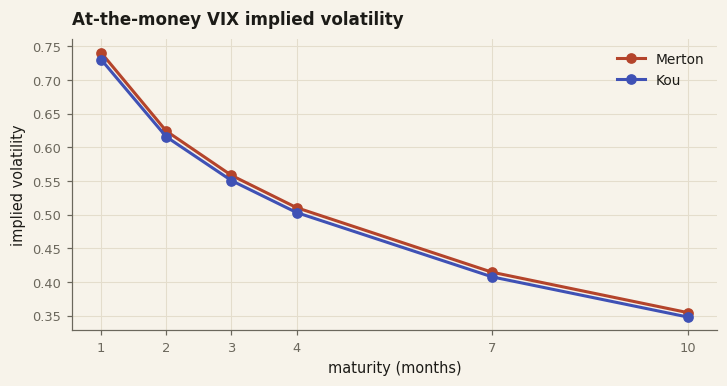

𓋹 PASS  Merton: ATM VIX volatility falls with maturity (0.74 → 0.35)
𓋹 PASS  Kou: ATM VIX volatility falls with maturity (0.73 → 0.35)


In [4]:
atm = {name: np.array([implied_volatility(model.vix_option_pricer(1.0, 1.0, T, R), 1.0, 1.0, T, R)
                       for T in TENOR_DATES[1:]]) for name, model in models.items()}
months = TENOR_DATES[1:] * 12
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for name, values in atm.items():
    ax.plot(months, values, "o-", color=COLORS[name], label=name)
ax.set(title="At-the-money VIX implied volatility", xlabel="maturity (months)", ylabel="implied volatility")
ax.set_xticks(months)
ax.legend()
plt.show()

for name, values in atm.items():
    st.check(np.all(np.diff(values) < 0), f"{name}: ATM VIX volatility falls with maturity "
             f"({values[0]:.2f} → {values[-1]:.2f})")

## 4 𓏽 The index implied-volatility surface

Now the index. Given the simulated variance and jump paths, the index is lognormal, so each
path contributes a Black–Scholes price and the option price is their average. The surface
shows the usual downward skew, steepest at short maturities.

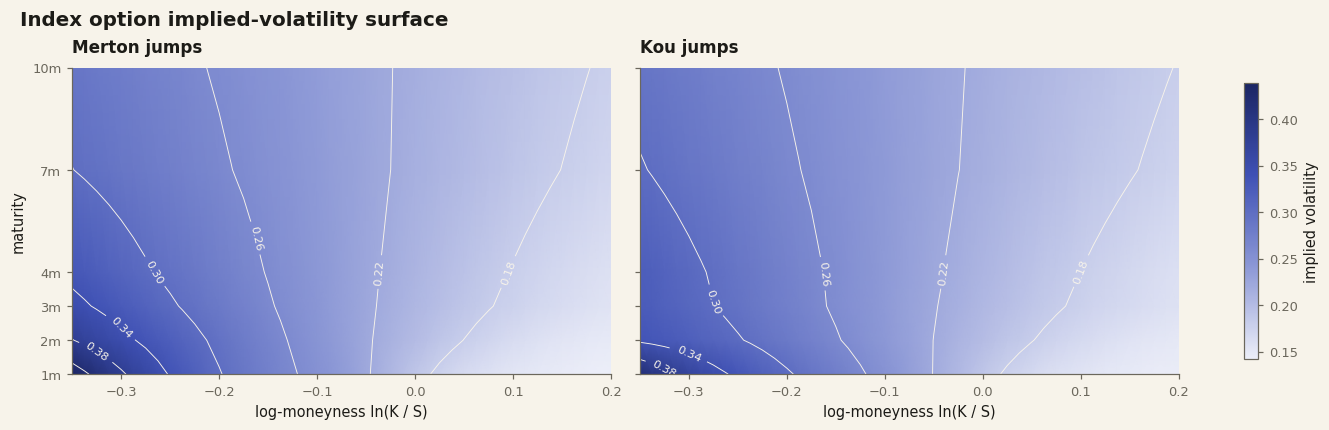

𓋹 PASS  Merton: index smile is skewed down at every maturity
𓋹 PASS  Merton: skew is steepest at the shortest maturity (0.098 vs 0.041)
𓋹 PASS  Kou: index smile is skewed down at every maturity
𓋹 PASS  Kou: skew is steepest at the shortest maturity (0.095 vs 0.040)


In [5]:
log_m = np.linspace(-0.35, 0.2, 45)
surfaces = {}
for name, model in models.items():
    surface = np.full((6, len(log_m)), np.nan)
    for j, T in enumerate(TENOR_DATES[1:]):
        ks = np.exp(log_m)
        otm = np.where(ks >= 1, "call", "put")
        calls = model.index_option_pricer(S0=1.0, strikes=ks, tenor_index=j + 1, r=R)
        prices = np.where(otm == "put", calls - 1.0 + ks, calls)        # parity, r = 0
        surface[j] = implied_volatility(prices, 1.0, ks, T, R, option_type=otm)
    surfaces[name] = surface

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
vmin, vmax = np.nanmin(list(surfaces.values())), np.nanmax(list(surfaces.values()))
for ax, (name, surface) in zip(axes, surfaces.items(), strict=True):
    mesh = ax.pcolormesh(log_m, months, surface, cmap=st.SEQUENTIAL, vmin=vmin, vmax=vmax, shading="gouraud")
    contours = ax.contour(log_m, months, surface, levels=np.arange(0.10, 0.60, 0.04), colors=st.PAPER, linewidths=0.6)
    ax.clabel(contours, fmt="%.2f", fontsize=7.5)
    ax.set(title=f"{name} jumps", xlabel="log-moneyness ln(K / S)")
    ax.set_yticks(months, LABELS)
    ax.grid(False)
axes[0].set_ylabel("maturity")
fig.colorbar(mesh, ax=axes, shrink=0.9, label="implied volatility")
fig.suptitle("Index option implied-volatility surface", x=0.01, ha="left")
plt.show()

for name, surface in surfaces.items():
    skew = np.array([np.interp(-0.1, log_m, row) - np.interp(0.1, log_m, row) for row in surface])
    st.check(np.all(skew > 0), f"{name}: index smile is skewed down at every maturity")
    st.check(skew[0] > skew[-1], f"{name}: skew is steepest at the shortest maturity "
             f"({skew[0]:.3f} vs {skew[-1]:.3f})")

## 5 𓏾 Both markets, one parameter set

This is the result the model exists for. At the same maturities and with the same
parameters, the index smile slopes down and the VIX smile slopes up, and both flatten with
maturity, as in the market.

The two jump laws give almost the same smiles. They differ mainly in the far VIX call wing,
where Kou's exponential tail prices calls higher.

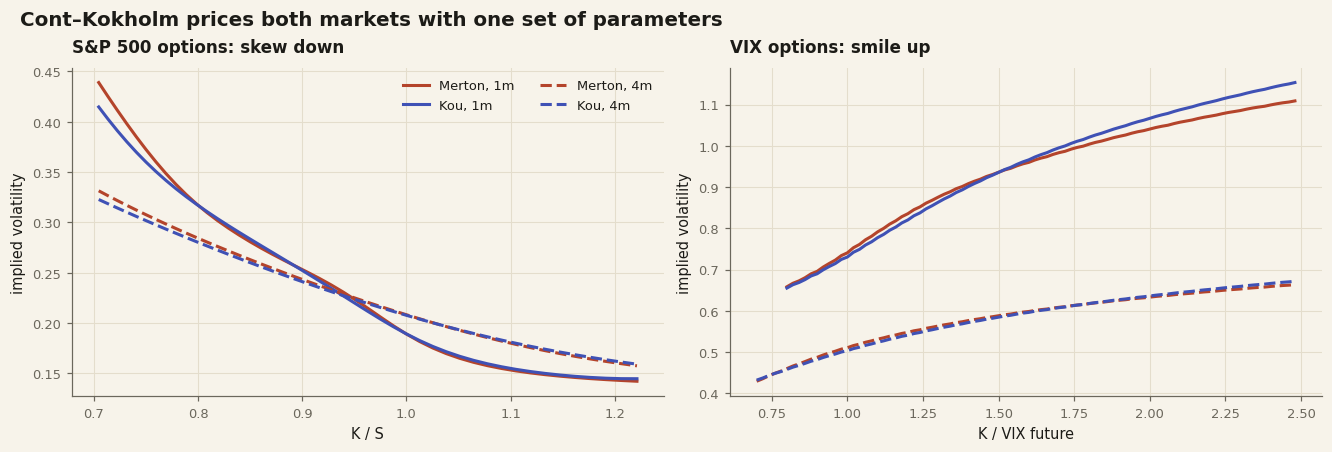

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for j, ls in [(0, "-"), (3, "--")]:
    for name in models:
        ax1.plot(np.exp(log_m), surfaces[name][j], color=COLORS[name], ls=ls,
                 label=f"{name}, {LABELS[j]}")
        ks, iv = vix_smiles[name, j]
        ax2.plot(ks, iv, color=COLORS[name], ls=ls, label=f"{name}, {LABELS[j]}")
ax1.set(title="S&P 500 options: skew down", xlabel="K / S", ylabel="implied volatility")
ax2.set(title="VIX options: smile up", xlabel="K / VIX future", ylabel="implied volatility")
ax1.legend(ncols=2, fontsize=8.5, loc="upper right")
fig.suptitle("Cont–Kokholm prices both markets with one set of parameters", x=0.01, ha="left")
st.save(fig, "cont_kokholm_joint_smiles")
plt.show()

In [7]:
st.summary()

8/8 checks passed
  𓋹 PASS  Merton: VIX smile rises from the money to 1.5× at every maturity
  𓋹 PASS  Kou: VIX smile rises from the money to 1.5× at every maturity
  𓋹 PASS  Merton: ATM VIX volatility falls with maturity (0.74 → 0.35)
  𓋹 PASS  Kou: ATM VIX volatility falls with maturity (0.73 → 0.35)
  𓋹 PASS  Merton: index smile is skewed down at every maturity
  𓋹 PASS  Merton: skew is steepest at the shortest maturity (0.098 vs 0.041)
  𓋹 PASS  Kou: index smile is skewed down at every maturity
  𓋹 PASS  Kou: skew is steepest at the shortest maturity (0.095 vs 0.040)
